# Session 8 lab: Discount, profit and advertising spend

<p class="lead">
Measure how discounts relate to profit in the retail orders, fit and interpret a regression of advertising spend against revenue, read its residuals, and learn to say clearly what a slope can and cannot promise.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/08_correlation_and_regression_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

Two managers have questions:

> *Commercial lead: "Do our discounts eat into profit? How strongly?"*
>
> *Marketing lead: "If one unit of search advertising brings in several units of revenue, why don't we double the budget?"*

Both questions are about **two measures moving together**. Your job is to measure the relationship honestly, and to say what it does **not** prove.

> **About the data**
>
> **Superstore** is a sample published by Tableau about a **fictitious** company. Sales and Profit are in the file's own **source monetary units**; the currency is not stated.
>
> **marketing_daily.csv** is **synthetic**: generated for this course, describing no real company, brand or platform. One row per day of 2025 × paid campaign. Amounts are in neutral **currency units**.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G5 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I5 |
| **Challenge** | Harder reasoning and debugging | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Draw a scatter plot and compute Pearson and Spearman correlation.
2. Aggregate to the right level **before** computing a ratio, and explain why the level changes the picture.
3. Fit a straight line with `np.polyfit`, and state its slope, R² and the range of the data in business language.
4. Read a residual plot and spot a missing factor.
5. Flag predictions that are extrapolations.
6. Explain why a regression slope from past data is an association, not the effect of spending more.

**Evidence you keep:** an **interpreted regression with one stated limitation** (I1–I3), plus your line-versus-order explanation (G4).

---

## Before you start

- Read the [Session 8 lecture](08_correlation_and_regression_lecture.md).
- Re-read [correlation is not causation](../foundations/misleading-statistics.md).
- Remember from the Session 5 lab: **profit ratio = total Profit ÷ total Sales**, a ratio of sums.

---

## Guided practice

### G1 (Core): Discount and profit ratio, line by line

Run the two setup cells, then load the order lines.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [3]:
import numpy as np

df = load_orders()
print("Rows (order lines):", len(df))
print("Different orders:  ", df["order_id"].nunique())
print("Lines with Sales of 0 or less:", (df["sales"] <= 0).sum())

Rows (order lines): 6815
Different orders:   3388
Lines with Sales of 0 or less: 0


Each line has a `discount` (a share of the list price: 0.2 means 20% off) and its own Sales and Profit. A line's **profit ratio** is its Profit ÷ its Sales. Because no line has zero Sales, every line has a ratio.

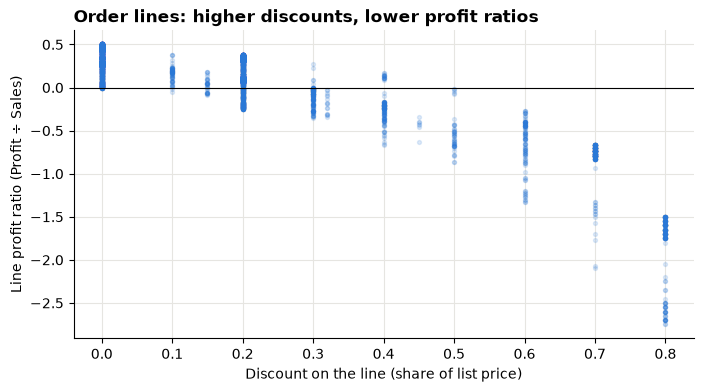

Different discount values: 12
Pearson r:  -0.865
Spearman:   -0.65


In [4]:
df["line_profit_ratio"] = df["profit"] / df["sales"]

ax = df.plot.scatter(x="discount", y="line_profit_ratio", s=8, alpha=0.15)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Order lines: higher discounts, lower profit ratios")
ax.set_xlabel("Discount on the line (share of list price)")
ax.set_ylabel("Line profit ratio (Profit ÷ Sales)")
plt.show()

print("Different discount values:", df["discount"].nunique())
print("Pearson r: ", round(df["discount"].corr(df["line_profit_ratio"]), 3))
print("Spearman:  ", round(df["discount"].rank().corr(df["line_profit_ratio"].rank()), 3))

> **What do you notice?**
>
> 1. Why do the dots form vertical **stripes**? (Look at the number of different discount values.)
> 2. Many dots sit on top of each other. Which discount values hold most of the lines?
> 3. Is the relationship positive or negative? Strong or weak?

### G2 (Core): Profit ratio by discount level

Because discount takes only a few values, a table can summarise the scatter. For each discount level we add up Sales and Profit and **then** divide: a ratio of sums, never an average of line ratios.

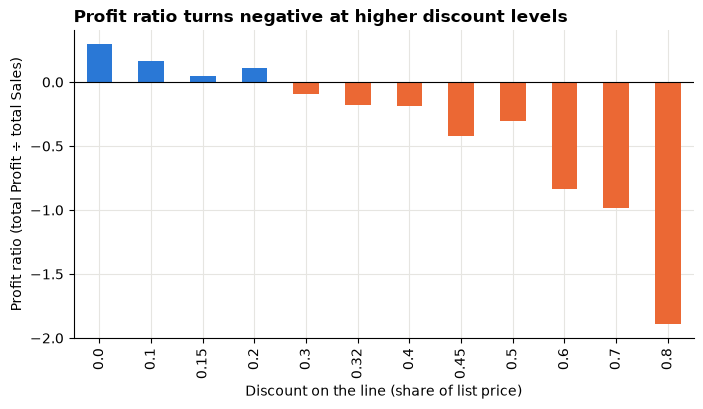

,lines,sales,profit,profit_ratio
discount,,,,
0.00,3296,"748,350.61","220,093.62",0.29
0.10,67,"35,773.77","5,796.92",0.16
0.15,36,"18,795.73",881.46,0.05
0.20,2464,"521,404.86","57,800.06",0.11
0.30,161,"72,640.59","-6,593.19",-0.09
0.32,16,"10,776.35","-1,898.91",-0.18
0.40,138,"82,397.71","-15,253.23",-0.18
0.45,7,"2,975.36","-1,264.67",-0.42
0.50,47,"45,117.10","-13,642.04",-0.30


In [5]:
by_discount = df.groupby("discount").agg(lines=("row_id", "count"), sales=("sales", "sum"), profit=("profit", "sum"))
by_discount["profit_ratio"] = by_discount["profit"] / by_discount["sales"]

ax = by_discount["profit_ratio"].plot.bar(color=["#2a78d6" if v >= 0 else "#eb6834" for v in by_discount["profit_ratio"]])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit ratio turns negative at higher discount levels")
ax.set_xlabel("Discount on the line (share of list price)")
ax.set_ylabel("Profit ratio (total Profit ÷ total Sales)")
plt.show()
by_discount.round(3)

Read the table above. Look at the **lines** column too: a level with few lines gives a less reliable ratio.

### G3 (Core): Aggregate to orders first

A manager thinks in **orders**, not lines. An order can mix discounted and full-price lines. To get one point per order:

1. Add up each order's Sales and Profit.
2. Order profit ratio = order Profit ÷ order Sales (a ratio of sums).
3. Order discount = Sales-weighted average of its lines' discounts: *sum of (discount × Sales) ÷ sum of Sales*. A big discounted line counts more than a small one.

Orders: 3388 | orders with more than one line: 1691


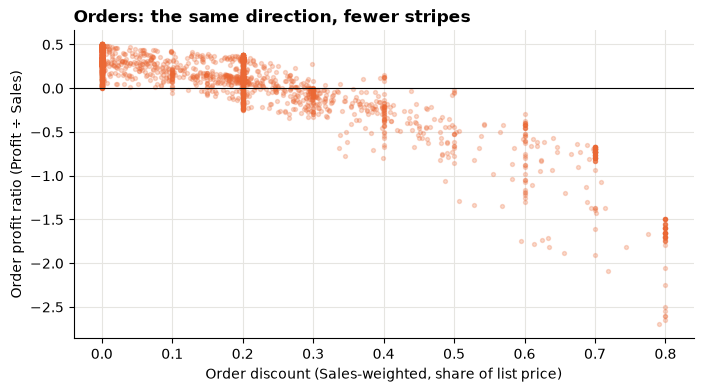

In [6]:
df["discount_x_sales"] = df["discount"] * df["sales"]
orders = df.groupby("order_id").agg(
    lines=("row_id", "count"),
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    discount_x_sales=("discount_x_sales", "sum"),
)
orders["order_discount"] = orders["discount_x_sales"] / orders["sales"]
orders["order_profit_ratio"] = orders["profit"] / orders["sales"]

print("Orders:", len(orders), "| orders with more than one line:", (orders["lines"] > 1).sum())

ax = orders.plot.scatter(x="order_discount", y="order_profit_ratio", s=8, alpha=0.25, color="#eb6834")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Orders: the same direction, fewer stripes")
ax.set_xlabel("Order discount (Sales-weighted, share of list price)")
ax.set_ylabel("Order profit ratio (Profit ÷ Sales)")
plt.show()

### G4 (Core): Why do the two pictures differ?

Put the two levels side by side.

In [7]:
def describe_level(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    return {
        "points": len(x),
        "Pearson r": x.corr(y),
        "Spearman": x.rank().corr(y.rank()),
        "slope": slope,
        "mean of ratios": y.mean(),
    }


levels = pd.DataFrame({
    "line level": describe_level(df["discount"], df["line_profit_ratio"]),
    "order level": describe_level(orders["order_discount"], orders["order_profit_ratio"]),
}).T.astype({"points": int})
print("Profit ratio of all Sales (total Profit ÷ total Sales):", round(df["profit"].sum() / df["sales"].sum(), 3))
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(levels)

Profit ratio of all Sales (total Profit ÷ total Sales): 0.124


,points,Pearson r,Spearman,slope,mean of ratios
line level,6815,-0.865,-0.650,-1.923,0.125
order level,3388,-0.863,-0.696,-1.855,0.116


Read the output above and discuss in pairs:

1. **Number of points.** An order with five lines is five dots at line level and one dot at order level. Which orders count more in the line picture?
2. **Mixing.** At order level, a discounted line and a full-price line are blended into one point. What happens to the stripes, and to the most extreme negative ratios?
3. **Averages.** Compare the two "mean of ratios" values with the profit ratio of all Sales printed above. Which number should a report use as *the* profit ratio? Why can an average of ratios not be trusted, even when it happens to land close?
4. **The question.** "Do discounted **products** lose money?" is a line question. "Do **orders** with deeper discounts lose money?" is an order question. Which did the commercial lead ask?

> **Rule**
>
> Decide the level of the question first, aggregate to that level, **then** compute ratios and correlations. State the level in every chart title and sentence.

### G5 (Core): Fit and interpret a line at order level

A slope per one whole unit of discount (100 percentage points) is hard to picture, so we also state it per 10 points.

Slope: -1.855 profit ratio per 1.0 of discount = -18.6 percentage points of profit ratio per 10 points of discount
Intercept: 0.403 (predicted profit ratio for an order with no discount)
R²: 0.745
Order discounts observed: 0.0 to 0.8


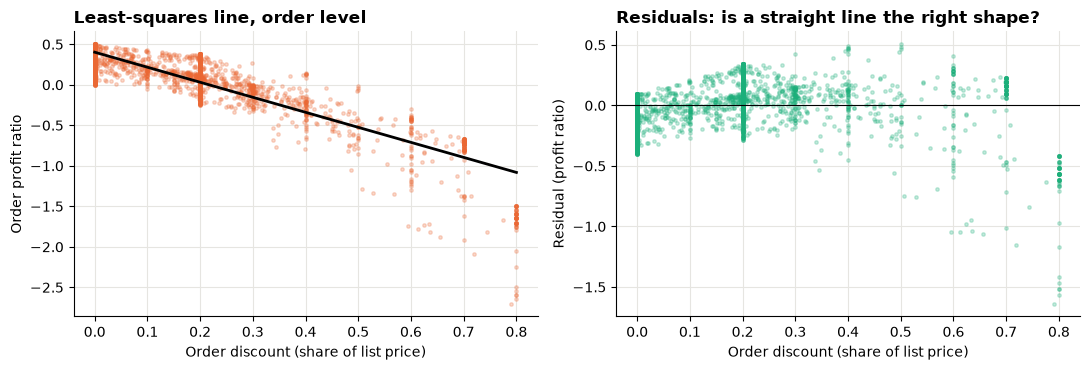

In [8]:
slope, intercept = np.polyfit(orders["order_discount"], orders["order_profit_ratio"], 1)
orders["predicted"] = intercept + slope * orders["order_discount"]
orders["residual"] = orders["order_profit_ratio"] - orders["predicted"]
r_squared = 1 - (orders["residual"] ** 2).sum() / ((orders["order_profit_ratio"] - orders["order_profit_ratio"].mean()) ** 2).sum()

print(f"Slope: {slope:.3f} profit ratio per 1.0 of discount "
      f"= {slope * 0.1 * 100:+.1f} percentage points of profit ratio per 10 points of discount")
print(f"Intercept: {intercept:.3f} (predicted profit ratio for an order with no discount)")
print(f"R²: {r_squared:.3f}")
print("Order discounts observed:", round(orders["order_discount"].min(), 2), "to", round(orders["order_discount"].max(), 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
xs = np.linspace(0, orders["order_discount"].max(), 50)
ax1.scatter(orders["order_discount"], orders["order_profit_ratio"], s=6, alpha=0.25, color="#eb6834")
ax1.plot(xs, intercept + slope * xs, color="black", linewidth=2)
ax1.set_title("Least-squares line, order level")
ax1.set_xlabel("Order discount (share of list price)")
ax1.set_ylabel("Order profit ratio")
ax2.scatter(orders["order_discount"], orders["residual"], s=6, alpha=0.25, color="#1baf7a")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Residuals: is a straight line the right shape?")
ax2.set_xlabel("Order discount (share of list price)")
ax2.set_ylabel("Residual (profit ratio)")
fig.tight_layout()
plt.show()

Here the intercept means something: an order with no discount is inside the data.

> **Write it down**
>
> Complete in your evidence log: *"Across all orders placed 2023–2025, each extra 10 points of order discount was **associated with** a profit ratio about ___ percentage points lower (R² = ___). The residual plot shows ___."*
>
> Then add **one limitation**. Ideas: discounts are not given at random (some product groups are discounted far more often, so product mix may be a confounder, see I5); the residuals show the line does not fit equally well everywhere; the data is a fictitious sample.

---

## Independent tasks

### I1 (Core): One campaign — fit and interpret a line

Load the advertising data. Days with zero spend cannot show what spend buys, so we keep only days with spend above zero.

In [9]:
mkt = load_marketing("marketing_daily.csv")
paid = mkt[mkt["spend"] > 0].copy()
print("Rows:", len(mkt), "| rows with spend > 0:", len(paid))
paid.groupby(["channel", "campaign_id"])["date"].count().rename("paid days")

Rows: 2555 | rows with spend > 0: 2516


channel  campaign_id
Display  DISP-01        362
Email    EML-01         353
Search   SRCH-01        360
         SRCH-02        359
Social   SOC-01         360
         SOC-02         359
Video    VID-01         363
Name: paid days, dtype: int64

The cell below fits daily attributed revenue against daily spend for **one campaign** and **one period**. We start with January–September, before the holiday season.

> **Your turn:** change the code in the next cell and run it again.

SRCH-01, months 1–9 of 2025, 270 paid days
Slope:      5.62 revenue units per unit of spend
Intercept:  1098
Pearson r:  0.623
R²:         0.388
Daily spend observed: 458 to 1,584
ROAS (total revenue ÷ total spend): 6.83


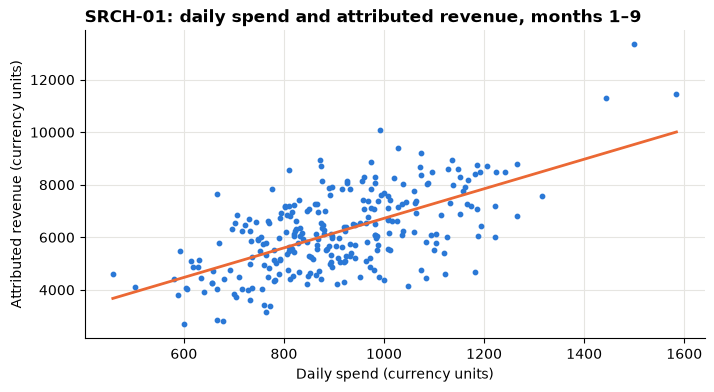

In [10]:
# 1. Run the cell for SRCH-01, January to September. Write the slope as one sentence.
# 2. Change campaign to another one (for example "SOC-01" or "DISP-01") and compare.
# 3. Later (I2) you will change last_month to 12 and run this cell again.
campaign = "SRCH-01"
first_month, last_month = 1, 9

one = paid[(paid["campaign_id"] == campaign)
           & (paid["date"].dt.month >= first_month) & (paid["date"].dt.month <= last_month)].copy()
slope, intercept = np.polyfit(one["spend"], one["attributed_revenue"], 1)
one["predicted"] = intercept + slope * one["spend"]
one["residual"] = one["attributed_revenue"] - one["predicted"]
ss_res = (one["residual"] ** 2).sum()
ss_tot = ((one["attributed_revenue"] - one["attributed_revenue"].mean()) ** 2).sum()
spend_min, spend_max = one["spend"].min(), one["spend"].max()

print(f"{campaign}, months {first_month}–{last_month} of 2025, {len(one)} paid days")
print(f"Slope:      {slope:.2f} revenue units per unit of spend")
print(f"Intercept:  {intercept:.0f}")
print(f"Pearson r:  {one['spend'].corr(one['attributed_revenue']):.3f}")
print(f"R²:         {1 - ss_res / ss_tot:.3f}")
print(f"Daily spend observed: {spend_min:,.0f} to {spend_max:,.0f}")
print(f"ROAS (total revenue ÷ total spend): {one['attributed_revenue'].sum() / one['spend'].sum():.2f}")

xs = np.linspace(spend_min, spend_max, 50)
ax = one.plot.scatter(x="spend", y="attributed_revenue", s=10)
ax.plot(xs, intercept + slope * xs, color="#eb6834", linewidth=2)
ax.set_title(f"{campaign}: daily spend and attributed revenue, months {first_month}–{last_month}")
ax.set_xlabel("Daily spend (currency units)")
ax.set_ylabel("Attributed revenue (currency units)")
plt.show()

> **Write it down**
>
> *"For [campaign], [months] 2025, each extra unit of daily spend was **associated with** about ___ more units of attributed revenue (R² = ___, daily spend between ___ and ___)."*
>
> The slope and the ROAS are different numbers. In one sentence each, say what they measure.

### I2 (Core): Read the residuals

> **Your turn:** change the code in the next cell and run it again.

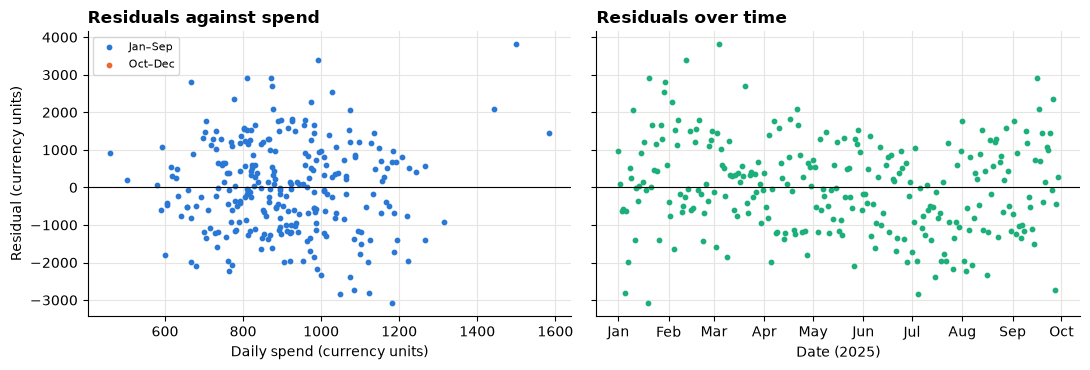

Average residual by month:
date
1    284.00
2    422.00
3    256.00
4     -4.00
5     25.00
6   -205.00
7   -856.00
8   -117.00
9    209.00


In [11]:
# 1. Run the cell. Is there a pattern in either panel?
# 2. Go back to I1, change last_month to 12, run I1 and then this cell again.
#    What happens to the slope? Where are October–December in the right-hand panel?
import matplotlib.dates as mdates

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
late = one["date"].dt.month >= 10
ax1.scatter(one["spend"][~late], one["residual"][~late], s=10, label="Jan–Sep")
ax1.scatter(one["spend"][late], one["residual"][late], s=10, color="#eb6834", label="Oct–Dec")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_title("Residuals against spend")
ax1.set_xlabel("Daily spend (currency units)")
ax1.set_ylabel("Residual (currency units)")
ax1.legend(fontsize=8)
ax2.scatter(one["date"], one["residual"], s=10, color="#1baf7a")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Residuals over time")
ax2.set_xlabel("Date (2025)")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.tight_layout()
plt.show()

print("Average residual by month:")
print(one.groupby(one["date"].dt.month)["residual"].mean().round(0).to_string())

> **What a pattern over time means**
>
> If residuals are mostly positive in some months and negative in others, something that changes with the calendar (season, promotions, budget changes) affects revenue **and** is not in the line. If that same factor also moved spend, the slope is confounded.

### I3 (Core): Predict, and flag extrapolation

Use the I1 line to predict revenue for a few daily budgets. The function flags any budget outside the observed range.

> **Your turn:** change the code in the next cell and run it again.

In [12]:
# 1. Run the cell. Which predictions can you defend?
# 2. Change the budgets: try the average daily spend, and double the highest spend.
budgets = [800, 1500, 3000]


def predict(spend_value):
    inside = spend_min <= spend_value <= spend_max
    note = "inside the observed range" if inside else "EXTRAPOLATION: outside the observed range"
    return pd.Series({"predicted revenue": intercept + slope * spend_value, "note": note})


print(f"{campaign}: observed daily spend {spend_min:,.0f} to {spend_max:,.0f}; average {one['spend'].mean():,.0f}")
pd.DataFrame({b: predict(b) for b in budgets}).T.rename_axis("daily budget")

SRCH-01: observed daily spend 458 to 1,584; average 908


,predicted revenue,note
daily budget,,
800,"5,597.58",inside the observed range
1500,"9,534.52",inside the observed range
3000,"17,970.82",EXTRAPOLATION: outside the observed range


Finish your **evidence**: your I1 sentence, plus one prediction **inside** the range, plus **one stated limitation**. For example: the slope is an association, not the effect of extra spend; it only holds for daily spend between the minimum and maximum you observed; the data are synthetic; attributed revenue may include customers who would have bought anyway.

### I4 (Stretch): Compare campaigns, and see what pooling hides

The same fit for every campaign, January–September, plus one line through all campaigns pooled together.

> **Your turn:** change the code in the next cell and run it again.

In [13]:
# 1. Run the cell. Rank the campaigns by slope. Is the ranking the same as by ROAS?
# 2. Why is the pooled slope so different from the Search campaigns' slopes?
# 3. Email's ROAS looks huge. Look at its spend range: why should you be careful ranking it first?
#    Then change last_month to 12 and compare.
last_month = 9
period = paid[paid["date"].dt.month <= last_month]


def fit_row(d):
    s, i = np.polyfit(d["spend"], d["attributed_revenue"], 1)
    return pd.Series({
        "days": len(d),
        "min spend": d["spend"].min(),
        "max spend": d["spend"].max(),
        "slope": s,
        "R²": d["spend"].corr(d["attributed_revenue"]) ** 2,
        "ROAS": d["attributed_revenue"].sum() / d["spend"].sum(),
    })


table = period.groupby("campaign_id").apply(fit_row, include_groups=False)
table.loc["All campaigns pooled"] = fit_row(period)
table.astype({"days": int}).round(2)

,days,min spend,max spend,slope,R²,ROAS
campaign_id,,,,,,
DISP-01,271,315.98,775.99,0.34,0.03,0.53
EML-01,264,25.69,61.80,23.15,0.14,24.81
SOC-01,271,658.42,"1,938.59",0.97,0.16,1.18
SOC-02,269,35.18,104.87,9.91,0.11,10.95
SRCH-01,270,458.03,"1,584.39",5.62,0.39,6.83
SRCH-02,269,333.13,"1,070.76",4.60,0.33,5.30
VID-01,271,248.93,681.08,0.45,0.07,0.32
All campaigns pooled,1885,25.69,"1,938.59",2.80,0.25,3.49


### I5 (Stretch): Is discount standing in for product type?

Discounts are not handed out at random. If some product groups are discounted more **and** have low profit ratios for other reasons, product type is a confounder. Compare the discount–profit relationship **within** each group.

> **Your turn:** change the code in the next cell and run it again.

In [14]:
# 1. Run the cell. Do the groups differ in how often they are discounted?
# 2. Is the correlation still negative within each group?
# 3. Change group to "sub_category". Which sub-categories are discounted most?
group = "category"


def group_row(d):
    return pd.Series({
        "lines": len(d),
        "share of lines discounted": (d["discount"] > 0).mean(),
        "profit ratio": d["profit"].sum() / d["sales"].sum(),
        "Pearson r (line level)": d["discount"].corr(d["line_profit_ratio"]),
    })


within = df.groupby(group).apply(group_row, include_groups=False).astype({"lines": int})
within.sort_values("share of lines discounted", ascending=False).round(3)

,lines,share of lines discounted,profit ratio,Pearson r (line level)
category,,,,
Furniture,1488,0.60,0.03,-0.89
Technology,1234,0.55,0.17,-0.76
Office Supplies,4093,0.48,0.18,-0.88


Write two sentences: one on whether the negative relationship survives **within** groups, one on why that still does not prove that cutting discounts would raise profit.

---

## Challenge

### C1 (Challenge): Anscombe's quartet

In 1973 the statistician Francis Anscombe published four small datasets to show why you must always **plot** your data. Here they are, typed in.

In [15]:
anscombe = pd.DataFrame({
    "x1": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y1": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
    "x2": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y2": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
    "x3": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y3": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
    "x4": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "y4": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89],
})

stats = {}
for k in "1234":
    x, y = anscombe[f"x{k}"], anscombe[f"y{k}"]
    s, i = np.polyfit(x, y, 1)
    stats[f"Set {k}"] = {"mean x": x.mean(), "mean y": y.mean(), "slope": s, "intercept": i,
                         "r": x.corr(y), "R²": x.corr(y) ** 2}
pd.DataFrame(stats).T.round(2)

,mean x,mean y,slope,intercept,r,R²
Set 1,9.00,7.50,0.50,3.00,0.82,0.67
Set 2,9.00,7.50,0.50,3.00,0.82,0.67
Set 3,9.00,7.50,0.50,3.00,0.82,0.67
Set 4,9.00,7.50,0.50,3.00,0.82,0.67


> **Predict, then reveal**
>
> The four sets share the same means, the same line and the same R². Do you expect the four scatter plots to look alike? Now run the next cell.

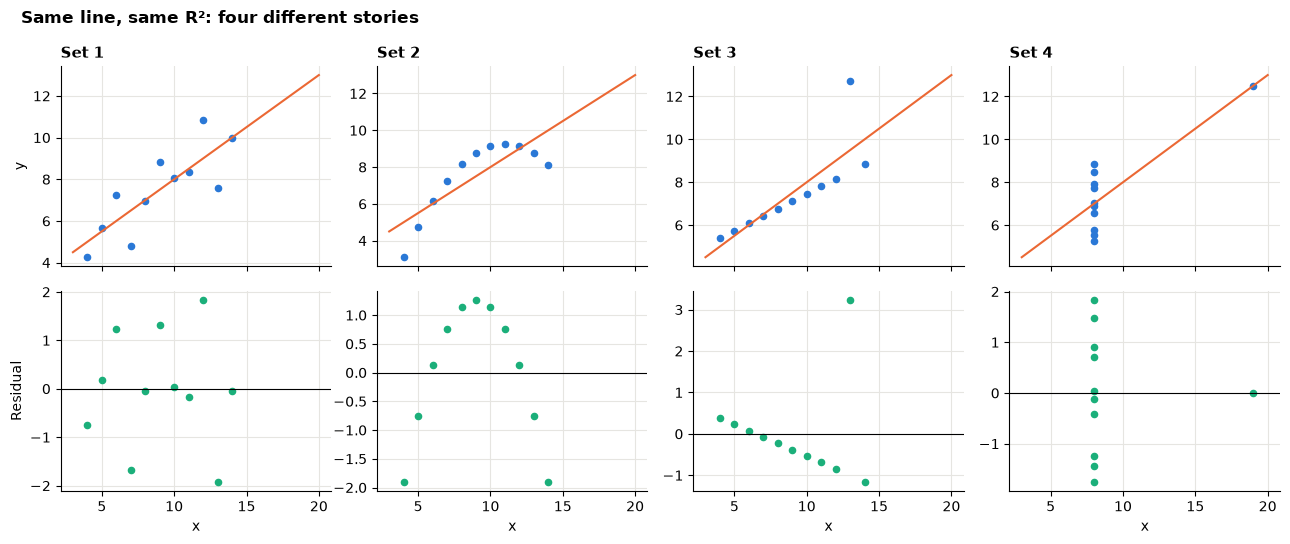

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
xs = np.linspace(3, 20, 50)
for col, k in enumerate("1234"):
    x, y = anscombe[f"x{k}"], anscombe[f"y{k}"]
    s, i = np.polyfit(x, y, 1)
    axes[0, col].scatter(x, y, s=20)
    axes[0, col].plot(xs, i + s * xs, color="#eb6834")
    axes[0, col].set_title(f"Set {k}", fontsize=11)
    axes[1, col].scatter(x, y - (i + s * x), s=20, color="#1baf7a")
    axes[1, col].axhline(0, color="black", linewidth=0.8)
    axes[1, col].set_xlabel("x")
axes[0, 0].set_ylabel("y")
axes[1, 0].set_ylabel("Residual")
fig.suptitle("Same line, same R²: four different stories", fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
plt.show()

For each set, write one sentence: is a straight line a fair summary? If not, what is wrong (a curve, one outlier, one high-leverage point)? Which residual plot tells you most clearly?

### C2 (Challenge): "Double the budget"

A colleague posts:

> *"I ran a regression on SRCH-01 for the whole of 2025. Every extra 1 unit of spend brings in more than ten units of revenue. Let's double the current daily budget: that's free money."*

Reproduce the colleague's number, then look at what they did not check.

> **Your turn:** change the code in the next cell and run it again.

In [17]:
# The colleague's analysis, plus some checks they did not make.
# 1. Find at least three problems with the claim. Use the lecture's Part 7 and Part 8.
# 2. Rewrite the colleague's message so it is accurate and states one limitation.
search = paid[paid["campaign_id"] == "SRCH-01"]
full_slope, full_intercept = np.polyfit(search["spend"], search["attributed_revenue"], 1)
jan_sep = search[search["date"].dt.month <= 9]
js_slope, _ = np.polyfit(jan_sep["spend"], jan_sep["attributed_revenue"], 1)

print(f"Colleague's slope, all of 2025:           {full_slope:.2f}")
print(f"Same campaign, January–September:         {js_slope:.2f}")
current = search.loc[search["date"].dt.month == 12, "spend"].mean()
print(f"Current daily budget (December average): {current:,.0f}")
print(f"Doubled current daily budget:            {2 * current:,.0f}")
print(f"Highest daily spend ever seen:            {search['spend'].max():,.0f}")
print("Average daily spend by quarter:")
print(search.groupby(search["date"].dt.quarter)["spend"].mean().round(0).to_string())

Colleague's slope, all of 2025:           13.31
Same campaign, January–September:         5.62
Current daily budget (December average): 1,475
Doubled current daily budget:            2,951
Highest daily spend ever seen:            2,150
Average daily spend by quarter:
date
1     926.00
2     885.00
3     913.00
4   1,306.00


> **Hint**
>
> Think about **what else** changed in the months with the highest spend, whether the doubled budget was **ever observed**, and whether "brings in" is a claim the data can support.

---

## Validation checklist

- [ ] Every scatter plot has a title, labelled axes and units.
- [ ] Profit ratios are ratios of sums at the level of the question (line, discount level, order).
- [ ] Order-level discount is weighted by Sales, and the level is stated in the sentence.
- [ ] Days with zero spend were excluded from the regressions, and you said so.
- [ ] Every slope is written with "associated with", its units, the period and the observed x-range.
- [ ] Every regression has a residual plot, and you described any pattern.
- [ ] Any prediction outside the observed range is labelled as extrapolation.
- [ ] No sentence claims that discounts or spend **cause** the change.

---

## Exit ticket

1. Why did the line-level and order-level discount pictures look different?
2. What does the slope of your I1 regression mean in one sentence, with units?
3. What did the residual plot tell you that the R² did not?
4. Why is "double the budget" an extrapolation?
5. Name one confounder for spend and revenue, and one for discount and profit ratio.

---

## Evidence to keep

- [ ] Line-level and order-level scatter plots with your explanation of the difference (G1–G4)
- [ ] Order-level slope sentence with one limitation (G5)
- [ ] **Interpreted regression with one stated limitation**: I1 sentence, residual plot, one in-range prediction (I1–I3)
- [ ] Campaign comparison and what pooling hides (I4, if attempted)
- [ ] Anscombe notes and the corrected "double the budget" message (C1, C2, if attempted)

Record in your evidence log the data versions, the period and campaign you used, and which days you excluded.

---

## After the lab

- Previous: [Session 8 lecture](08_correlation_and_regression_lecture.md).
- Next: [Session 9 lecture: Sampling, uncertainty and experiments](09_sampling_and_experiments_lecture.md).